### Predict Fail Quality Audit - Modeling
### Capstone Project Two : Springboard Data Science career track

## Modeling approach

**Goal.** Build a final model that predicts which wafers will fail (`fail = 1`) from the process sensor features, as defined in the problem identification step.

**Why these models.** The target is binary and the features are numeric, so I compared three different types of classifier:

| Model | Type | Why it was chosen |
|---|---|---|
| Logistic Regression | Linear, with feature selection | Simple, interpretable baseline |
| Random Forest | Bagged trees | Handles many noisy features and non-linear effects |
| LightGBM | Gradient boosting | Strong on tabular data |

**Handling the imbalance.** Only 17 of the 314 test wafers (5.4%) fail. All models use class weights. A model that always predicts "pass" would reach 94.6% accuracy and find no failures, so accuracy is not used to pick the model.

**Hyperparameter tuning.** Each model was tuned with `GridSearchCV` (Logistic Regression, LightGBM) or `RandomizedSearchCV` (Random Forest). The data is time-ordered, so the folds use `TimeSeriesSplit` (train on the past, validate on the future, gap = 10). The test set is the latest 20% of wafers and was used only once, after tuning.

**Metrics used to choose the final model**
1. **PR AUC (average precision)**, the main metric. It focuses on the rare failure class. A random model scores about **0.054** (the failure rate).
2. **ROC AUC**, which measures overall ranking quality. A random model scores 0.5.
3. **Recall and precision on failures**, which show how many failures are caught and how many alarms are real.


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (accuracy_score, roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score, confusion_matrix)
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

In [2]:
DATA_PATH   = Path("../outputs")   
TARGET      = "fail"                 # pass/fail column (1 = fail, 0 = pass)
TIME_COL    = "timestamp"                    # name of a timestamp column, or None if rows are already time-ordered
TIME_ORDERED = True                   # True -> chronological split; False -> stratified random split
TIME_FEATURES = False                 # True -> add cyclical hour / day-of-week features from the timestamp
SEED        = 42
TRAIN_DATA = 'train_processed.csv'
TEST_DATA ='test_processed.csv'
X_train = pd.read_csv(DATA_PATH / TRAIN_DATA)
X_test = pd.read_csv(DATA_PATH / TEST_DATA)

y_train = X_train[TARGET].astype(int)
X_train = X_train.drop(columns=[TARGET])

y_test = X_test[TARGET].astype(int)
X_test = X_test.drop(columns=[TARGET])

print(f'Train data shape:', X_train.shape)
print(f'Test data shape:', X_test.shape)
X_test.head()


Train data shape: (1253, 464)
Test data shape: (314, 464)


,S000,S001,S002,S003,S004,S006,S007,S008,S009,S010,...,S556_isna,S557_isna,S562_isna,S563_isna,S564_isna,S565_isna,S566_isna,S567_isna,S568_isna,S569_isna
0,0.201018,0.377056,-0.881895,-0.705198,-1.205848,0.558563,0.698836,-1.484683,-0.497049,-1.294271,...,-0.505481,-0.505481,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563
1,-0.381422,1.285684,-0.881895,-0.705198,-1.205848,0.558563,0.698836,-1.247863,-0.281360,0.580353,...,-0.505481,-0.505481,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563
2,-0.639094,0.186295,1.170879,0.426379,2.001477,-2.207311,0.013843,-1.653840,-2.377594,0.334866,...,-0.505481,-0.505481,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563
3,-1.473333,-0.100280,1.237307,0.516059,-0.787194,-2.078150,0.329993,0.105395,0.716205,0.156331,...,-0.505481,-0.505481,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563
4,-1.829522,-0.754105,0.363563,0.334840,0.014161,-0.752454,0.698836,-0.162315,-0.031968,3.094135,...,-0.505481,-0.505481,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563,-0.526563


In [3]:
def plot_confusion_matrix(y_true, y_pred, title=""):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    plt.figure(figsize=(5, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Pass (0)", "Fail (1)"],
                yticklabels=["Pass (0)", "Fail (1)"])
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.title(f"Confusion Matrix ({title})")
    plt.show()

## GridsearchCV logistic regression

In [4]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

pipe = Pipeline([
    ("sel", SelectKBest(f_classif)),
    ("lr", LogisticRegression(solver="liblinear", class_weight="balanced", max_iter=2000)),
])

param_grid = {
    "sel__k": [20, 50, 100, "all"],
    "lr__C": [0.001, 0.01, 0.1, 1, 10],
    "lr__penalty": ["l1", "l2"],
}

gs = GridSearchCV(
    pipe, param_grid,
    cv=TimeSeriesSplit(n_splits=5, gap=10),   # past -> future only, never shuffled
    scoring="average_precision",              # PR AUC, suited to 17/314 imbalance
    n_jobs=-1,
    error_score=np.nan,                       # skip folds that have no positives
    refit=True,                               # refits best params on all of X_train
)
gs.fit(X_train, y_train)

print("best params :", gs.best_params_)
print(f"best CV PR AUC: {gs.best_score_:.3f}")

# evaluate once on the test set
best = gs.best_estimator_
y_prob = best.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)
print(f"Test ROC AUC {roc_auc_score(y_test, y_prob):.3f} | "
      f"Test PR AUC {average_precision_score(y_test, y_prob):.3f} | "
      f"Acc {accuracy_score(y_test, y_pred):.3f} | "
      f"Recall {recall_score(y_test, y_pred, zero_division=0):.3f} | "
      f"Precision {precision_score(y_test, y_pred, zero_division=0):.3f} | "
      f"F1 {f1_score(y_test, y_pred, zero_division=0):.3f}")

best params : {'lr__C': 1, 'lr__penalty': 'l1', 'sel__k': 50}
best CV PR AUC: 0.182
Test ROC AUC 0.573 | Test PR AUC 0.166 | Acc 0.828 | Recall 0.294 | Precision 0.106 | F1 0.156


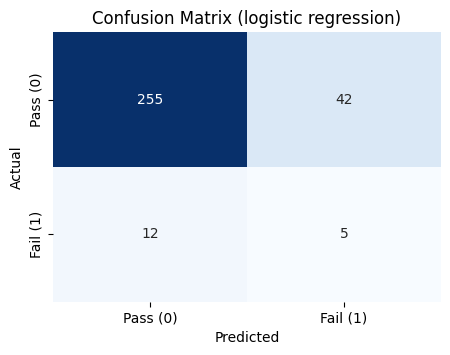

In [5]:
plot_confusion_matrix(y_test, y_pred, "logistic regression")

In [6]:
lgbm = LGBMClassifier(
    subsample=0.8, subsample_freq=1,
    class_weight="balanced", random_state=42, verbose=-1, n_jobs=1,
)

param_grid = {
    "n_estimators":      [100, 300],
    "learning_rate":     [0.03, 0.1],
    "num_leaves":        [4, 8],
    "min_child_samples": [10, 20],
    "colsample_bytree":  [0.5, 0.8],
    "reg_lambda":        [1, 5],
}

gs = GridSearchCV(
    lgbm, param_grid,
    cv=TimeSeriesSplit(n_splits=5, gap=10),   # past -> future only
    scoring="average_precision",              # PR AUC for 17/314 imbalance
    n_jobs=-1,
    error_score=np.nan,                       # folds with no positives -> NaN
    refit=True,
)
gs.fit(X_train, y_train)

print("best params :", gs.best_params_)
print(f"best CV PR AUC: {gs.best_score_:.3f}")

best = gs.best_estimator_
y_prob = best.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)
print(f"Test ROC AUC {roc_auc_score(y_test, y_prob):.3f} | "
      f"Test PR AUC {average_precision_score(y_test, y_prob):.3f} | "
      f"Acc {accuracy_score(y_test, y_pred):.3f} | "
      f"Recall {recall_score(y_test, y_pred, zero_division=0):.3f} | "
      f"Precision {precision_score(y_test, y_pred, zero_division=0):.3f} | "
      f"F1 {f1_score(y_test, y_pred, zero_division=0):.3f}")

best params : {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'min_child_samples': 20, 'n_estimators': 100, 'num_leaves': 8, 'reg_lambda': 5}
best CV PR AUC: 0.247
Test ROC AUC 0.580 | Test PR AUC 0.078 | Acc 0.930 | Recall 0.000 | Precision 0.000 | F1 0.000


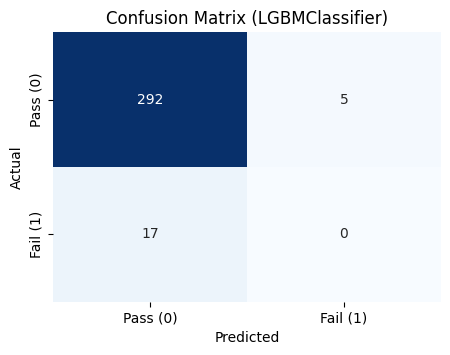

In [7]:
plot_confusion_matrix(y_test, y_pred, "LGBMClassifier")

In [8]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

rf = RandomForestClassifier(
    class_weight="balanced_subsample", n_jobs=1, random_state=42,
)

param_dist = {
    "n_estimators":      [200, 300, 500, 800],
    "max_depth":         [None, 3, 5, 8, 12],
    "min_samples_leaf":  randint(2, 15),
    "min_samples_split": randint(2, 20),
    "max_features":      ["sqrt", "log2", 0.1, 0.3],
    "max_samples":       [None, 0.5, 0.8],      # row subsampling per tree
}

rs = RandomizedSearchCV(
    rf, param_dist,
    n_iter=40,                                  # 40 random configs x 5 folds = 200 fits
    cv=TimeSeriesSplit(n_splits=5, gap=10),     # past -> future only
    scoring="average_precision",                # PR AUC for 17/314 imbalance
    n_jobs=-1,
    random_state=42,
    error_score=np.nan,                         # folds with no positives -> NaN
    refit=True,
)
rs.fit(X_train, y_train)

print("best params :", rs.best_params_)
print(f"best CV PR AUC: {rs.best_score_:.3f}")

best = rs.best_estimator_
y_prob = best.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)
print(f"Test ROC AUC {roc_auc_score(y_test, y_prob):.3f} | "
      f"Test PR AUC {average_precision_score(y_test, y_prob):.3f} | "
      f"Acc {accuracy_score(y_test, y_pred):.3f} | "
      f"Recall {recall_score(y_test, y_pred, zero_division=0):.3f} | "
      f"Precision {precision_score(y_test, y_pred, zero_division=0):.3f} | "
      f"F1 {f1_score(y_test, y_pred, zero_division=0):.3f}")

best params : {'max_depth': 8, 'max_features': 0.3, 'max_samples': 0.5, 'min_samples_leaf': 12, 'min_samples_split': 8, 'n_estimators': 300}
best CV PR AUC: 0.217
Test ROC AUC 0.556 | Test PR AUC 0.068 | Acc 0.946 | Recall 0.000 | Precision 0.000 | F1 0.000


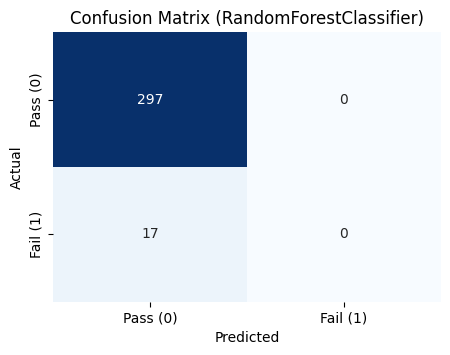

In [9]:
plot_confusion_matrix(y_test, y_pred, "RandomForestClassifier")

## Model comparison and final choice

| Model | Best hyperparameters | CV PR AUC | Test PR AUC | Test ROC AUC | Recall (fail) | Precision (fail) |
|---|---|---|---|---|---|---|
| **Logistic Regression** | `C=1`, L1 penalty, top 50 features | 0.182 | **0.166** | 0.573 | **0.294** | 0.106 |
| LightGBM | 100 trees, lr 0.03, 8 leaves | **0.247** | 0.078 | 0.580 | 0.000 | 0.000 |
| Random Forest | 800 trees, depth 12, `max_features=0.3` | 0.214 | 0.070 | 0.554 | 0.000 | 0.000 |

Reference: the random baseline is PR AUC = 0.054 and ROC AUC = 0.5.

### What the comparison shows
- **LightGBM and Random Forest looked best in cross-validation but did not hold up on the test period.** Their test PR AUC (0.078 and 0.070) is close to the random baseline, and neither caught a single failure (recall = 0).
- **Logistic Regression is the only model that stayed useful on the later wafers.** Its test PR AUC (0.166) is about 3 times the random baseline, and it caught 5 of the 17 failures (recall 0.29).
- All three ROC AUC values are between 0.55 and 0.58, only slightly above random.

### Final model: **Logistic Regression (L1, C = 1, 50 selected features)**
It is the only model with a clearly better-than-random PR AUC on the future test data, and the only one that detects failures. It is also the simplest and the easiest to explain. The tree models fit the training period better but seem to have learned patterns that do not carry forward in time.

### Limitations
- The test set has only 17 failures, so these differences are uncertain. One more or fewer detected failure changes recall by about 6 points.
- Cross-validation preferred LightGBM, so this choice rests on the test result. It should be confirmed with more data or a bootstrap confidence interval.
- Precision is low (0.11): about 9 in 10 alerts are false alarms, and the overall predictive signal is weak. The model is best seen as a screening aid, not an automatic reject rule.
